# XLA Backend

## Inspecting the HLO Output

In [1]:
import jax
import jax.numpy as jnp


def f(x):
    return jnp.sin(x) + jnp.cos(x)

In [2]:
# Get the StableHLO representation for this function
lowered = jax.jit(f).lower(jnp.ones(4))
print(lowered.as_text())

module @jit_f attributes {mhlo.num_partitions = 1 : i32, mhlo.num_replicas = 1 : i32} {
  func.func public @main(%arg0: tensor<4xf32>) -> (tensor<4xf32> {jax.result_info = "result"}) {
    %0 = stablehlo.sine %arg0 : tensor<4xf32>
    %1 = stablehlo.cosine %arg0 : tensor<4xf32>
    %2 = stablehlo.add %0, %1 : tensor<4xf32>
    return %2 : tensor<4xf32>
  }
}



## A More Involved HLO : Softmax

In [3]:
def softmax(x):
    x_shifted = x - jnp.max(x)
    e_x = jnp.exp(x_shifted)
    return e_x / jnp.sum(e_x)

In [4]:
lowered = jax.jit(softmax).lower(jnp.ones(4))
print(lowered.as_text())

module @jit_softmax attributes {mhlo.num_partitions = 1 : i32, mhlo.num_replicas = 1 : i32} {
  func.func public @main(%arg0: tensor<4xf32>) -> (tensor<4xf32> {jax.result_info = "result"}) {
    %cst = stablehlo.constant dense<0xFF800000> : tensor<f32>
    %0 = stablehlo.reduce(%arg0 init: %cst) applies stablehlo.maximum across dimensions = [0] : (tensor<4xf32>, tensor<f32>) -> tensor<f32>
    %1 = stablehlo.broadcast_in_dim %0, dims = [] : (tensor<f32>) -> tensor<4xf32>
    %2 = stablehlo.subtract %arg0, %1 : tensor<4xf32>
    %3 = stablehlo.exponential %2 : tensor<4xf32>
    %cst_0 = stablehlo.constant dense<0.000000e+00> : tensor<f32>
    %4 = stablehlo.reduce(%3 init: %cst_0) applies stablehlo.add across dimensions = [0] : (tensor<4xf32>, tensor<f32>) -> tensor<f32>
    %5 = stablehlo.broadcast_in_dim %4, dims = [] : (tensor<f32>) -> tensor<4xf32>
    %6 = stablehlo.divide %3, %5 : tensor<4xf32>
    return %6 : tensor<4xf32>
  }
}



## Observing Operator Fusion

In [5]:
import time
import numpy as np


def elementwise_chain_numpy(x):
    x = np.sin(x)
    x = np.exp(x)
    x = x * 2.0
    x = np.tanh(x)
    return x


def elementwise_chain_jax(x):
    x = jnp.sin(x)
    x = jnp.exp(x)
    x = x * 2.0
    x = jnp.tanh(x)
    return x


elementwise_chain_jit = jax.jit(elementwise_chain_jax)

In [6]:
x_np = np.ones((2000, 2000))
x_jnp = jnp.ones((2000, 2000))
_ = elementwise_chain_jit(x_jnp).block_until_ready()

In [7]:
start = time.perf_counter()
for _ in range(10):
    elementwise_chain_numpy(x_np)
print(f"NumPy (no fusion): {(time.perf_counter() - start) / 10 * 1000:.2f} ms per call")

NumPy (no fusion): 77.30 ms per call


In [8]:
start = time.perf_counter()
for _ in range(10):
    elementwise_chain_jit(x_jnp).block_until_ready()
print(f"JAX JIT (fused): {(time.perf_counter() - start) / 10 * 1000:.2f} ms per call")

JAX JIT (fused): 5.58 ms per call


In [9]:
lowered = jax.jit(elementwise_chain_jax).lower(x_jnp)
print(lowered.as_text())

module @jit_elementwise_chain_jax attributes {mhlo.num_partitions = 1 : i32, mhlo.num_replicas = 1 : i32} {
  func.func public @main(%arg0: tensor<2000x2000xf32>) -> (tensor<2000x2000xf32> {jax.result_info = "result"}) {
    %0 = stablehlo.sine %arg0 : tensor<2000x2000xf32>
    %1 = stablehlo.exponential %0 : tensor<2000x2000xf32>
    %cst = stablehlo.constant dense<2.000000e+00> : tensor<f32>
    %2 = stablehlo.broadcast_in_dim %cst, dims = [] : (tensor<f32>) -> tensor<2000x2000xf32>
    %3 = stablehlo.multiply %1, %2 : tensor<2000x2000xf32>
    %4 = stablehlo.tanh %3 : tensor<2000x2000xf32>
    return %4 : tensor<2000x2000xf32>
  }
}



## Compilation from StableHLO to Machine Code

In [10]:
@jax.jit
def f(x):
    return jnp.sum(jnp.sin(x) ** 2)

In [11]:
lowered = f.lower(jnp.ones(4))
print(lowered.as_text())

module @jit_f attributes {mhlo.num_partitions = 1 : i32, mhlo.num_replicas = 1 : i32} {
  func.func public @main(%arg0: tensor<4xf32>) -> (tensor<f32> {jax.result_info = "result"}) {
    %0 = stablehlo.sine %arg0 : tensor<4xf32>
    %1 = stablehlo.multiply %0, %0 : tensor<4xf32>
    %cst = stablehlo.constant dense<0.000000e+00> : tensor<f32>
    %2 = stablehlo.reduce(%1 init: %cst) applies stablehlo.add across dimensions = [0] : (tensor<4xf32>, tensor<f32>) -> tensor<f32>
    return %2 : tensor<f32>
  }
}



In [12]:
compiled = lowered.compile()
print(f"compiled: {compiled}")
print(f"type(compiled): {type(compiled).__name__}")

compiled: <jax._src.stages.Compiled object at 0x000001CCB67035F0>
type(compiled): Compiled


In [13]:
dir(compiled)

['__annotations__',
 '__call__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__slots__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_call',
 '_executable',
 '_input_layouts_flat',
 '_input_shardings_flat',
 '_no_kwargs',
 '_output_formats_flat',
 '_params',
 'args_info',
 'as_text',
 'call',
 'cost_analysis',
 'donate_argnums',
 'in_avals',
 'in_tree',
 'input_formats',
 'input_shardings',
 'memory_analysis',
 'out_info',
 'out_tree',
 'output_formats',
 'output_shardings',
 'runtime_executable']

In [14]:
compiled(jnp.ones(4))

Array(2.8322935, dtype=float32)

## XLA on Different Hardware

In [15]:
print(f"Available devices: {jax.devices()}")
print(f"Default backend: {jax.default_backend()}")

Available devices: [CpuDevice(id=0)]
Default backend: cpu


In [16]:
@jax.jit
def matmul(A, B):
    return A @ B


A = jnp.ones((512, 512))
B = jnp.ones((512, 512))

start = time.perf_counter()
for _ in range(20):
    matmul(A, B).block_until_ready()
print(
    f"Matrix multiply ({jax.default_backend()}): {(time.perf_counter() - start) / 20 * 1000:.2f} ms per call"
)

Matrix multiply (cpu): 1.85 ms per call


## Layout Assignment: Watching the Backend Decide

In [17]:
@jax.jit
def matmul(A, B):
    return A @ B.T

In [18]:
lowered = matmul.lower(jnp.ones((3, 4)), jnp.ones((3, 4)))
print(lowered.as_text())

module @jit_matmul attributes {mhlo.num_partitions = 1 : i32, mhlo.num_replicas = 1 : i32} {
  func.func public @main(%arg0: tensor<3x4xf32>, %arg1: tensor<3x4xf32>) -> (tensor<3x3xf32> {jax.result_info = "result"}) {
    %0 = stablehlo.transpose %arg1, dims = [1, 0] : (tensor<3x4xf32>) -> tensor<4x3xf32>
    %1 = stablehlo.dot_general %arg0, %0, contracting_dims = [1] x [0], precision = [DEFAULT, DEFAULT] : (tensor<3x4xf32>, tensor<4x3xf32>) -> tensor<3x3xf32>
    return %1 : tensor<3x3xf32>
  }
}



In [19]:
compiled = lowered.compile()
print(f"compiled as text: {compiled.as_text()}")

compiled as text: HloModule jit_matmul, is_scheduled=true, entry_computation_layout={(f32[3,4]{1,0}, f32[3,4]{1,0})->f32[3,3]{1,0}}, allow_spmd_sharding_propagation_to_parameters={true,true}, allow_spmd_sharding_propagation_to_output={true}

FileNames
1 "<frozen runpy>"
2 "C:\\Users\\user\\AppData\\Local\\Temp\\ipykernel_15412\\2767011309.py"
3 "C:\\Users\\user\\AppData\\Local\\Temp\\ipykernel_15412\\1162114016.py"

FunctionNames
1 "_run_module_as_main"
2 "_run_code"
3 "<module>"
4 "matmul"

FileLocations
1 {file_name_id=1 function_name_id=1 line=198 end_line=199 column=11 end_column=42}
2 {file_name_id=1 function_name_id=2 line=88 end_line=88 column=4 end_column=27}
3 {file_name_id=2 function_name_id=3 line=1 end_line=1 column=10 end_column=58}
4 {file_name_id=3 function_name_id=4 line=3 end_line=3 column=15 end_column=18}
5 {file_name_id=3 function_name_id=4 line=3 end_line=3 column=11 end_column=18}

StackFrames
1 {file_location_id=1 parent_frame_id=1}
2 {file_location_id=2 parent_f

## Benchmarking the Price of Fusion

In [21]:
def chain(x, k):
    for _ in range(k):
        x = 0.25 * x**3 + 0.75 * x
    return x

chain_jit = jax.jit(chain, static_argnums=1)

In [22]:
x = jnp.ones((2000, 2000))
ks = [1, 2, 4, 8, 16, 32]
eager_ms, jit_ms = [], []

In [23]:
for k in ks:
    _ = chain(x, k).block_until_ready()
    start = time.perf_counter()
    for _ in range(20):
        chain(x, k).block_until_ready()
    eager_ms.append((time.perf_counter() - start) / 20 * 1000)

    _ = chain_jit(x, k).block_until_ready()
    start = time.perf_counter()
    for _ in range(20):
        chain_jit(x, k).block_until_ready()
    jit_ms.append((time.perf_counter() - start) / 20 * 1000)    

    print(f"k={k:2d}: eager {eager_ms[-1]:7.2f} ms | jit {jit_ms[-1]:6.2f} ms")

k= 1: eager    5.69 ms | jit   1.55 ms
k= 2: eager   11.46 ms | jit   1.54 ms
k= 4: eager   21.02 ms | jit   1.63 ms
k= 8: eager   44.82 ms | jit   1.80 ms
k=16: eager   90.46 ms | jit   2.36 ms
k=32: eager  182.72 ms | jit   3.69 ms


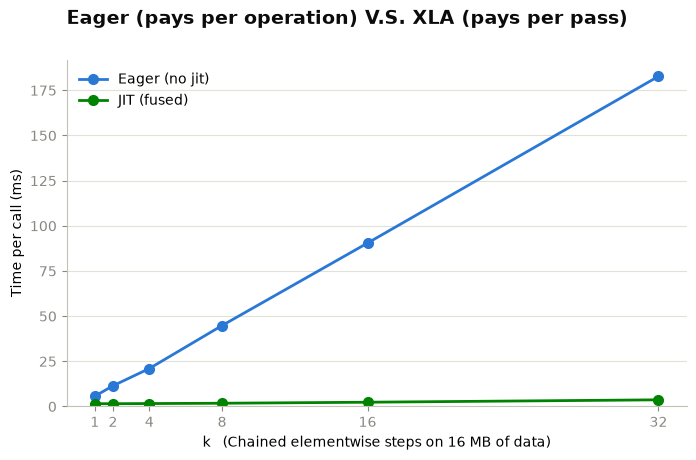

In [24]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    ks,
    eager_ms,
    color="#2a78d6",
    linewidth=2,
    marker="o",
    markersize=7,
    label="Eager (no jit)",
)
ax.plot(
    ks,
    jit_ms,
    color="#008300",
    linewidth=2,
    marker="o",
    markersize=7,
    label="JIT (fused)",
)

ax.set_xticks(ks)
ax.set_xlabel("k   (Chained elementwise steps on 16 MB of data)")
ax.set_ylabel("Time per call (ms)")
ax.set_title(
    "Eager (pays per operation) V.S. XLA (pays per pass)",
    loc="left",
    fontsize=14,
    fontweight="bold",
    color="#0b0b0b",
    pad=26,
)

ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.set_ylim(bottom=0)

plt.show()